# Noise simulation

ObjectNat has three noise models with the same inputs (source level `source_noise_db` in dB at 1 m and
characteristic frequency `geometric_mean_freq_hz` in Hz, per source or as arguments):

1. `simulate_noise_grid`: levels on a receiver grid, direct paths, first-order reflections and diffraction around
   building corners, energy summation; point, line and polygon sources;
2. `simulate_noise`: wave-front model for point sources with multiple reflections and vegetation;
3. `calculate_simplified_noise_frame`: visibility masks and distance decay, for a quick estimate.

The sources here are a street (a line through the open space between blocks) and two point sources.

The last section, *Your own area*, shows what to replace to get the same pictures for another territory.

In [1]:
# !pip install objectnat pyarrow matplotlib

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
from matplotlib import colors as mcolors

from objectnat import calculate_simplified_noise_frame, config, simulate_noise, simulate_noise_grid

config.set_enable_tqdm(False)

obstacles = gpd.read_parquet("examples_data/buildings.parquet")  # EPSG:32636, metres
trees = gpd.read_parquet("examples_data/trees.parquet")

In [3]:
import matplotlib.pyplot as plt
import numpy as np


def map_axes(ax, bounds, step=100):
    """Show `bounds` (x0, y0, x1, y1 in metres) with axes in metres from the lower-left corner."""
    x0, y0, x1, y1 = bounds
    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)
    ax.set_aspect("equal")
    ax.set_xticks(x0 + np.arange(0, x1 - x0 + 1, step), [f"{v:g}" for v in np.arange(0, x1 - x0 + 1, step)])
    ax.set_yticks(y0 + np.arange(0, y1 - y0 + 1, step), [f"{v:g}" for v in np.arange(0, y1 - y0 + 1, step)])
    ax.set_xlabel("x, m")
    ax.set_ylabel("y, m")
    ax.tick_params(labelsize=8)

In [4]:
centre = (346050, 6647450)
square = shapely.box(centre[0] - 300, centre[1] - 300, centre[0] + 300, centre[1] + 300)
scene = obstacles[obstacles.intersects(square.buffer(200))]
vegetation = trees[trees.intersects(square)]

street = shapely.LineString([(345805, 6647230), (345805, 6647650)])  # street between two blocks
points = gpd.GeoDataFrame(
    {"source_noise_db": [95.0, 85.0], "geometric_mean_freq_hz": [2000.0, 500.0]},
    geometry=[shapely.Point(346145, 6647505), shapely.Point(346240, 6647260)],
    crs=obstacles.crs,
)
road = gpd.GeoDataFrame({"source_noise_db": [80.0], "geometric_mean_freq_hz": [1000.0]}, geometry=[street], crs=obstacles.crs)
sources = pd.concat([road, points], ignore_index=True)
print("street crosses a building:", scene.intersects(street).any(),
      "| point inside a building:", scene.contains(points.union_all()).any())
sources

street crosses a building: False | point inside a building: False


,source_noise_db,geometric_mean_freq_hz,geometry
0,80.0,1000.0,"LINESTRING (345805 6647230, 345805 6647650)"
1,95.0,2000.0,POINT (346145 6647505)
2,85.0,500.0,POINT (346240 6647260)


In [5]:
def show_levels(ax, bands, title, lo=40, hi=95):
    cmap = plt.get_cmap("magma_r", int((hi - lo) / 5))
    norm = mcolors.Normalize(lo, hi)
    bands.plot(ax=ax, column="noise_level", cmap=cmap, norm=norm, linewidth=0)
    vegetation.clip(square).plot(ax=ax, facecolor="none", edgecolor="#2ca25f", hatch="///", linewidth=0.5)
    scene.clip(square).plot(ax=ax, color="#bdbdbd", edgecolor="#8c8c8c", linewidth=0.3)
    sources.plot(ax=ax, color="#2b7bba", linewidth=1.5, markersize=25)
    map_axes(ax, square.bounds)
    ax.set_title(title)
    return plt.cm.ScalarMappable(norm=norm, cmap=cmap)

## 1. Receiver grid

Receivers every `grid_step` metres; the street is sampled every `source_spacing` metres (default 5) so that it
follows the line-source law. Levels are grouped into bands of `db_sim_step` dB (`noise_level` is the upper bound of
the band); `output="both"` also returns the receivers with their exact levels, `output="receivers"` only them.

In [6]:
import time

start = time.perf_counter()
grid_bands, receivers = simulate_noise_grid(
    sources, scene, trees=vegetation, grid_step=2, db_sim_step=5, target_noise_db=40,
    reflections=True, reflection_max_dist=50, output="both",
)
print(f"{len(receivers)} receivers above 40 dB in {time.perf_counter() - start:.1f} s")
receivers["noise_level"].describe().round(1)

45555 receivers above 40 dB in 3.5 s


count    45555.0
mean        51.8
std          9.2
min         40.0
25%         44.6
50%         49.6
75%         56.8
max         92.1
Name: noise_level, dtype: float64

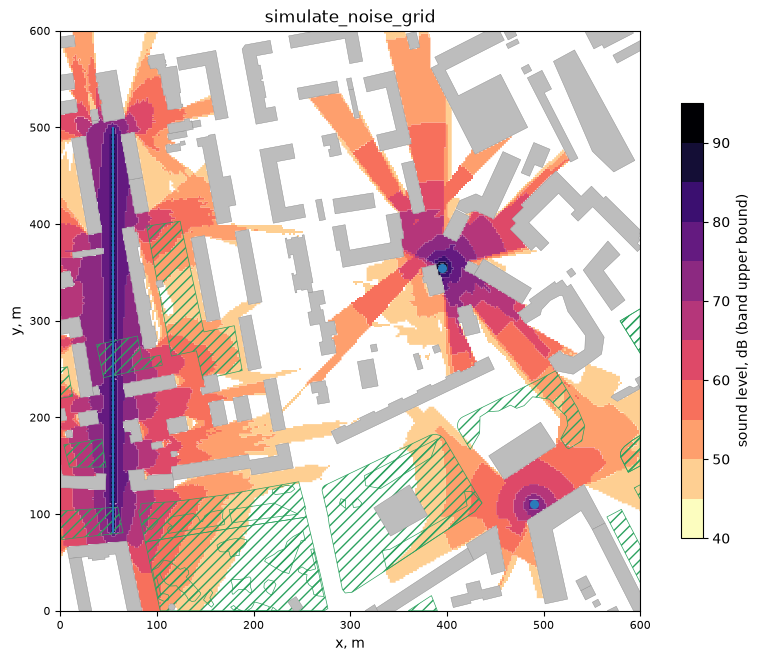

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 6.5), constrained_layout=True)
sm = show_levels(ax, grid_bands, "simulate_noise_grid")
fig.colorbar(sm, ax=ax, shrink=0.75, label="sound level, dB (band upper bound)")
plt.show()

The bands are `db_sim_step` wide because they are polygons; the receivers hold the exact, continuous level.
`rasterize` turns them into a raster on the calculation grid, which shows what the secondary paths add: compared
with `reflections=False`, reflections add 1–3 dB along the street canyon and form new beams where the direct sound
is blocked; compared with `diffraction=False`, diffraction fills the shadows beside the beams and behind the
buildings next to the point sources (at most 20 dB below the free field around one corner, 25 dB around two).

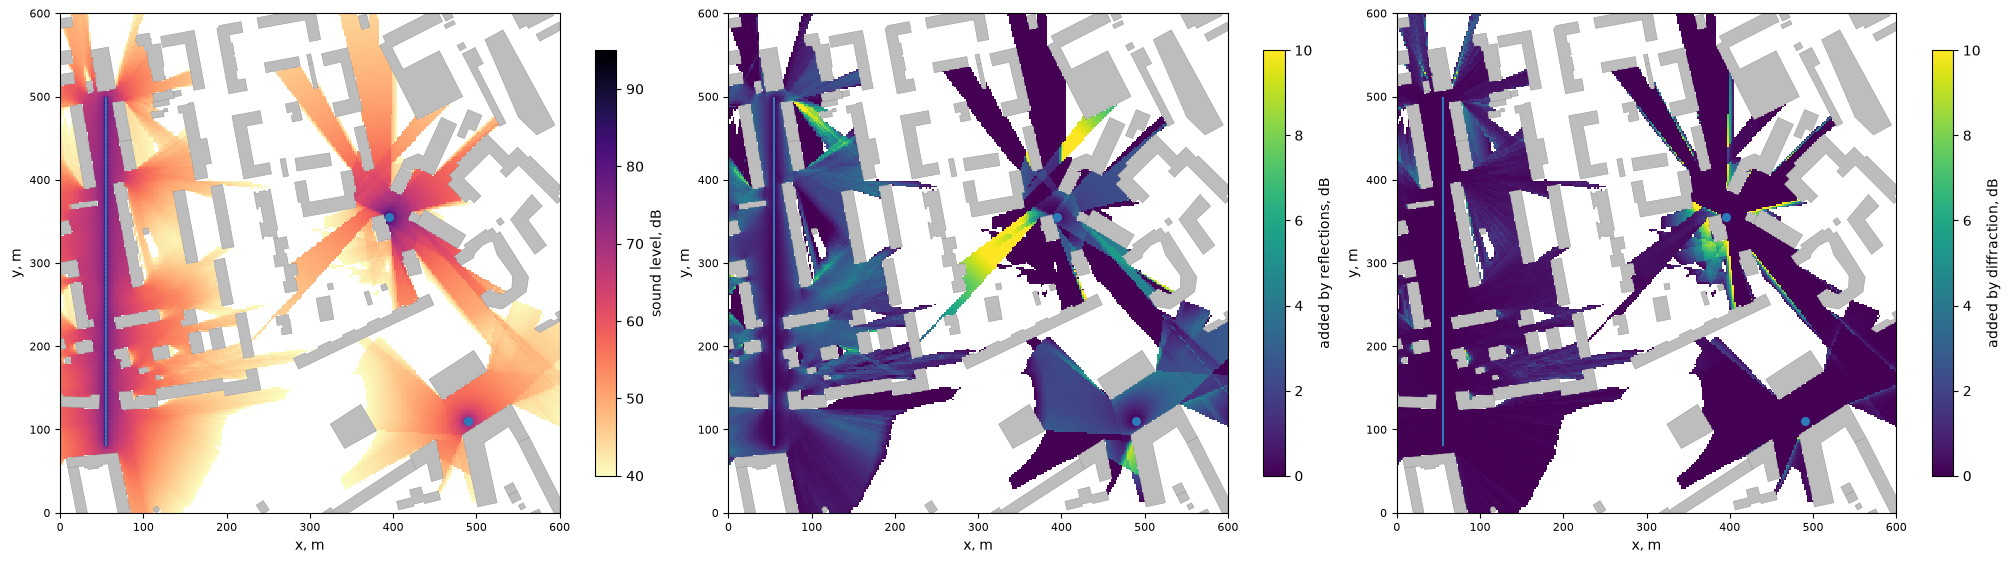

In [8]:
from objectnat import rasterize

common = dict(trees=vegetation, grid_step=2, target_noise_db=40, output="receivers")
no_reflections = simulate_noise_grid(sources, scene, reflections=False, **common)
no_diffraction = simulate_noise_grid(sources, scene, diffraction=False, **common)
# the runs share one grid; receivers reached only by the compared paths are compared with the 40 dB floor
key = lambda g: pd.MultiIndex.from_arrays([g.geometry.x.round(2), g.geometry.y.round(2)])
for column, other in [("by_reflections", no_reflections), ("by_diffraction", no_diffraction)]:
    other_level = pd.Series(other["noise_level"].to_numpy(), index=key(other))
    receivers[column] = receivers["noise_level"] - other_level.reindex(key(receivers)).fillna(40.0).to_numpy()

fig, axs = plt.subplots(1, 3, figsize=(20, 6), constrained_layout=True)
for ax, column, cmap, (lo, hi), label in [
    (axs[0], "noise_level", "magma_r", (40, 95), "sound level, dB"),
    (axs[1], "by_reflections", "viridis", (0, 10), "added by reflections, dB"),
    (axs[2], "by_diffraction", "viridis", (0, 10), "added by diffraction, dB"),
]:
    im = rasterize(receivers, column).plot(ax=ax, cmap=cmap, vmin=lo, vmax=hi)
    fig.colorbar(im, ax=ax, shrink=0.75, label=label)
    scene.clip(square).plot(ax=ax, color="#bdbdbd", edgecolor="#8c8c8c", linewidth=0.3)
    sources.plot(ax=ax, color="#2b7bba", linewidth=1.5, markersize=25)
    map_axes(ax, square.bounds)
plt.show()

Two equal sources add +3 dB in this model, because energies are summed. Without reflections and diffraction the area
behind the buildings stays silent:

In [9]:
direct_only = simulate_noise_grid(sources, scene, trees=vegetation, grid_step=2, db_sim_step=5, reflections=False,
                                  diffraction=False)
area = pd.DataFrame({
    "all paths, ha": grid_bands.set_index("noise_level").area / 1e4,
    "direct only, ha": direct_only.set_index("noise_level").area / 1e4,
}).fillna(0)
area.round(2)

,"all paths, ha","direct only, ha"
noise_level,,
45.0,4.90,3.87
50.0,4.52,3.71
55.0,3.32,2.57
60.0,2.01,1.57
65.0,1.20,1.01
70.0,1.08,0.92
75.0,0.70,0.55
80.0,0.26,0.22
85.0,0.08,0.08


## 2. Wave-front simulation

`simulate_noise` takes point sources only. It propagates the sound in layers of `db_sim_step` dB with up to
`reflection_n` reflections and vegetation attenuation.

In [10]:
start = time.perf_counter()
wave = simulate_noise(
    source_points=points,
    obstacles=scene,
    standart_absorb_ratio=0.05,
    trees=vegetation,
    tree_resolution=4,
    air_temperature=20,
    target_noise_db=40,
    db_sim_step=5,
    reflection_n=2,
    dead_area_r=5,
    use_parallel=False,
)
print(f"{time.perf_counter() - start:.1f} s, {len(wave)} level bands")

3.4 s, 72 level bands


## 3. Simplified noise frame

`calculate_simplified_noise_frame` accepts point, line and polygon sources and needs no propagation simulation;
obstacles act only as line-of-sight masks.

0.2 s


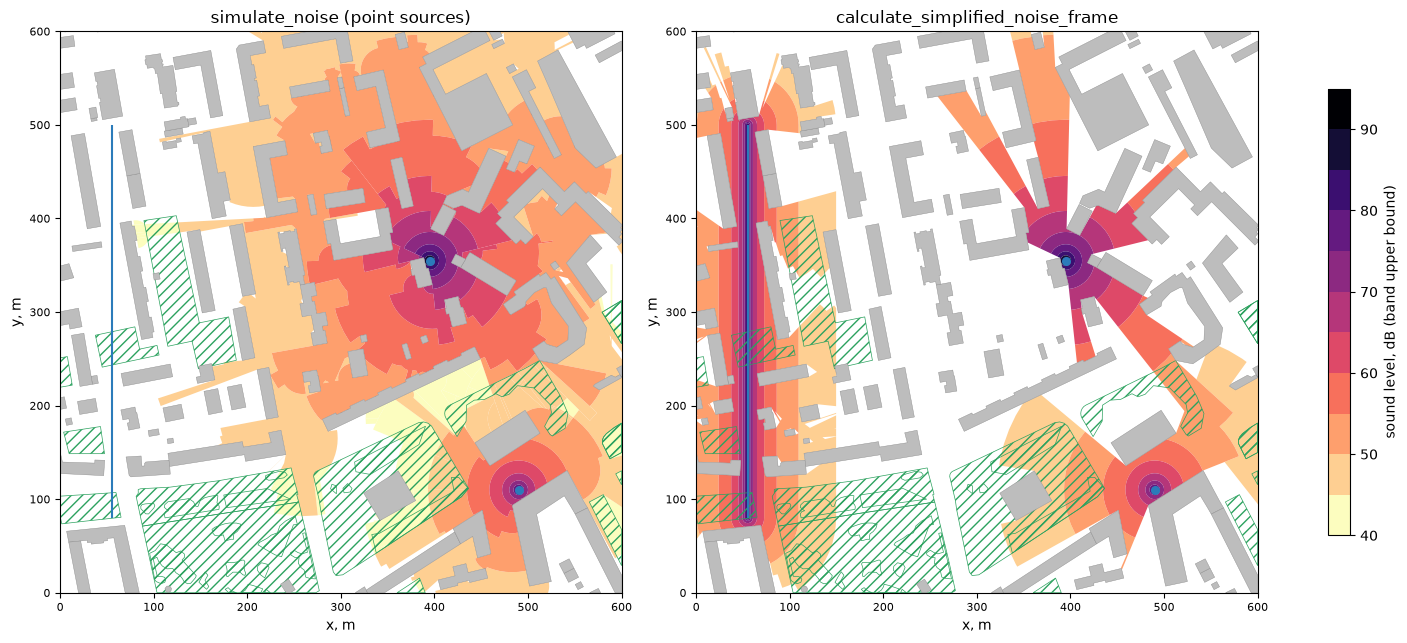

In [11]:
start = time.perf_counter()
frame = calculate_simplified_noise_frame(sources, scene, air_temperature=20, target_noise_db=40, db_sim_step=5)
print(f"{time.perf_counter() - start:.1f} s")

fig, axs = plt.subplots(1, 2, figsize=(14, 6.5), constrained_layout=True)
show_levels(axs[0], wave, "simulate_noise (point sources)")
sm = show_levels(axs[1], frame, "calculate_simplified_noise_frame")
fig.colorbar(sm, ax=axs, shrink=0.75, label="sound level, dB (band upper bound)")
plt.show()

The models differ: `simulate_noise_grid` and `simulate_noise` include reflections, the simplified frame does not;
`simulate_noise` and the simplified frame combine sources by the band maximum, `simulate_noise_grid` by energy
summation. Only `simulate_noise_grid` includes diffraction around building corners; none of them models ground
effect. See the [noise page](../noise.rst).

## 4. Your own area

Sources (points, roads as lines, sites as polygons, with `source_noise_db` and `geometric_mean_freq_hz`) and
buildings: the receivers as a raster of exact levels. `Raster.plot` draws the raster, `Raster.explore` puts it on a web map with a colour bar and `Raster.to_geotiff`
writes a GeoTIFF for GIS (requires `rasterio`).

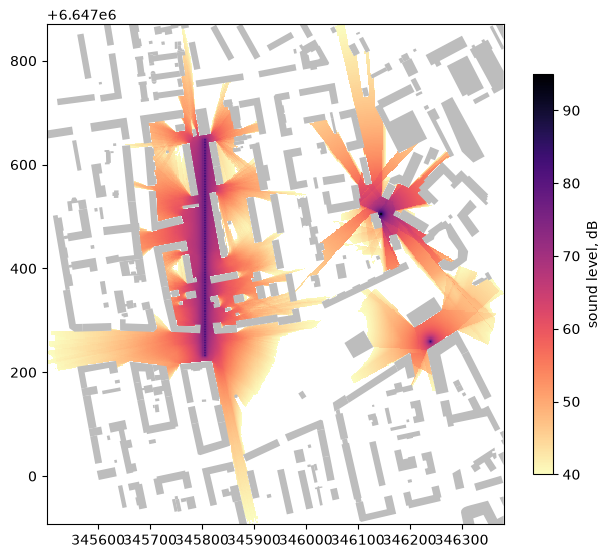

In [12]:
my_sources = sources    # your sources, any CRS
my_buildings = scene    # your buildings (and trees=... for vegetation)

level = rasterize(simulate_noise_grid(my_sources, my_buildings, trees=vegetation, grid_step=2, output="receivers"),
                  "noise_level")
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = level.plot(ax=ax, cmap="magma_r", vmin=40, vmax=95)
my_buildings.clip(shapely.box(*level.bounds)).plot(ax=ax, color="#bdbdbd", linewidth=0)
fig.colorbar(im, ax=ax, shrink=0.8, label="sound level, dB")
plt.show()
# level.to_geotiff("my_noise.tif")  # for GIS


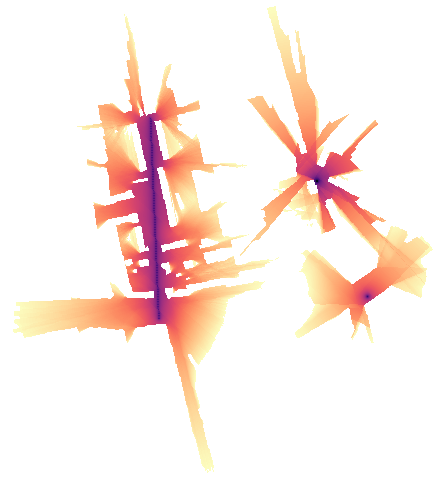

In [13]:
level.explore(cmap="magma_r", vmin=40, vmax=95, name="sound level, dB")